11/2/2026 Gottlieb

The previous notebook implemented Vásquez and Farinelli's arbitrage detector for cash and two risky assets. The purpose of this notebook is to organize those calculations into reusable functions. We will also generalize the simulation to multiple Brownian shocks and the detector to multiple low-variance directions. These functions will later be moved into a Python file.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

First, let's produce Brownian increments. For each independent shock $a$, an increment over a time interval $\Delta t$ has the following distribution (Eq. 3):
$$\Delta W_a \sim N(0,\Delta t)$$

The increments will be stored with time steps as rows and shocks as columns, so `n_shocks` counts independent Brownian motions. A shock is a source of randomness; an exposure measures an asset's response to that shock. Brownian paths are then cumulative sums of these increments, starting at zero:
$$W_a(t_j)=\sum_{i=1}^j\Delta W_{a,i}, \qquad W_a(0)=0$$

In [2]:
def brownian_increments(n_steps, n_shocks, dt, rng):
    """Generate independent Brownian increments with shape (steps, shocks)."""
    # Use positive integer step/shock counts, dt > 0, and a NumPy random generator.
    return rng.normal(0.0, np.sqrt(dt), size=(n_steps, n_shocks))


def brownian_paths(increments):
    """Convert a (steps, shocks) array into paths, including the initial zero."""
    # Use finite increments shaped (n_steps, n_shocks).
    increments = np.asarray(increments, dtype=float)
    initial = np.zeros((1, increments.shape[1]))
    return np.vstack([initial, np.cumsum(increments, axis=0)])

For multiple shocks, the volatility exposure matrix $\sigma$ has assets as rows and shocks as columns: $\sigma_\mu^a$ is asset $\mu$'s exposure to shock $a$. For $N$ assets and $d$ shocks, $\sigma$ is $N\times d$. The covariance matrix $\Omega$ is $N\times N$, with equivalent matrix and indexed forms (Proposition 2.2):
$$\Omega=\sigma\sigma^T, \qquad \Omega_{\mu\nu}=\sum_a\sigma_\mu^a\sigma_\nu^a$$
Its diagonal $\Omega_{\mu\mu}=\sum_a(\sigma_\mu^a)^2$ gives each asset's variance per unit time.

With constant coefficients, the exact geometric Brownian motion update is the increment form of (Eq. 106), solving (Eq. 2):
$$\ln\left(\frac{X_\mu(t+\Delta t)}{X_\mu(t)}\right)=\left(\alpha_\mu-\frac12\sum_a(\sigma_\mu^a)^2\right)\Delta t+\sum_a\sigma_\mu^a\Delta W_a$$

Our simulation function takes the increments explicitly. This lets us compare different drifts or exposures using the same shocks. To include cash, give its row zero drift and zero exposure. Prices include the initial observation, so $T$ increments produce $T+1$ price observations.

In [3]:
def simulate_gbm(initial_prices, alpha, sigma, dt, increments, assets=None):
    """Simulate constant-coefficient GBM; sigma has shape (assets, shocks)."""
    # Use finite initial_prices and alpha vectors of length N; initial prices and dt > 0.
    # sigma: (N, n_shocks); increments: (n_steps, n_shocks).
    # If supplied, assets should contain N column names.
    initial_prices = np.asarray(initial_prices, dtype=float)
    alpha = np.asarray(alpha, dtype=float)
    sigma = np.asarray(sigma, dtype=float)
    increments = np.asarray(increments, dtype=float)

    variance = np.sum(sigma**2, axis=1)
    log_r = (alpha - 0.5 * variance) * dt + increments @ sigma.T
    log_growth = np.vstack([np.zeros(len(initial_prices)), np.cumsum(log_r, axis=0)])
    return pd.DataFrame(
        initial_prices * np.exp(log_growth),
        index=pd.RangeIndex(len(increments) + 1, name="Step"),
        columns=assets,
    )

Now let's organize the calculations used by the detector. Log returns are used to estimate covariance (Eq. 93), while simple returns are used to measure the portfolio's next drift (Eq. 89):
$$\ell_{\mu,t}=\log\left(\frac{X_\mu(t)}{X_\mu(t-1)}\right), \qquad r_{\mu,t}=\frac{X_\mu(t)}{X_\mu(t-1)}-1$$
Here $r$ denotes simple returns; the capital $R$ below will denote centered log returns.

In [4]:
def calculate_returns(prices):
    """Return log and simple returns, labeled by their ending observation."""
    # Use a DataFrame of finite positive prices: time rows, asset columns.
    # Use unique asset names and unique, increasing observation labels.
    ratios = prices / prices.shift(1)
    return np.log(ratios).iloc[1:], (ratios - 1).iloc[1:]

The covariance estimator remains the same as in the previous notebook (Eq. 93):
$$\hat\Omega=\frac{R^TR}{L}, \qquad \hat\Omega_{\mu\nu}=\frac1L\sum_{t=1}^L R_{t\mu}R_{t\nu}=\frac1L\sum_{t=1}^L(\ell_{\mu,t}-\bar\ell_\mu)(\ell_{\nu,t}-\bar\ell_\nu), \qquad R_{t\mu}=\ell_{\mu,t}-\bar\ell_\mu$$
where $R$ contains log returns after subtracting each asset's mean within the window. The denominator is $L$, rather than $L-1$, to follow the paper. This is covariance per observation interval; dividing by $\Delta t$ would convert it to covariance per unit time.

We then enforce the zero-cost condition (Eq. 88) using the compact equivalent of (Eq. 85):
$$P=I-\frac1N U, \qquad \hat G=P\hat\Omega P$$
where $U$ is the $N\times N$ all-ones matrix.

In [5]:
def estimate_covariance(window):
    """Estimate log-return covariance per step, using denominator L (Eq. 93)."""
    # Use finite log returns shaped (L, N), with at least two rows.
    values = np.asarray(window, dtype=float)
    R = values - values.mean(axis=0)
    return R.T @ R / len(R)


def project_covariance(Omega):
    """Construct G = P Omega P, equivalent to (Eq. 85)."""
    # Use a finite symmetric covariance matrix shaped (N, N), with N >= 2.
    Omega = np.asarray(Omega, dtype=float)
    N = len(Omega)
    P = np.eye(N) - np.ones((N, N)) / N
    G = P @ Omega @ P
    return (G + G.T) / 2

We return to the previous notebook's method: diagonalize $\hat G$ (Eq. 86), with eigenvalues in increasing order (Eq. 87), then subtract each candidate's mean to remove the all-ones direction (Eq. 88). Skip candidates that become zero. Keep the first $k$ surviving directions. The paper specifies an eigendecomposition, but does not prescribe a specific method. Here $k$ is an assumption about the null-space dimension.

In [6]:
def estimate_directions(Omega, k):
    """Select k orthonormal zero-cost directions from G (Eqs. 86-88)."""
    # Use a covariance matrix and an integer k between 1 and N - 1.
    G = project_covariance(Omega)
    N = len(G)
    _, eigenvectors = np.linalg.eigh(G)
    directions = []
    for vector in eigenvectors.T:
        candidate = vector - vector.mean()
        for direction in directions:
            candidate -= (candidate @ direction) * direction
        length = np.linalg.norm(candidate)
        if length > 1e-8:
            directions.append(candidate / length)
        if len(directions) == k:
            break

    J = np.column_stack(directions)
    # Recompute eigenvalues after removing the trivial component.
    eigenvalues = np.diag(J.T @ G @ J)
    return J, eigenvalues

Before multiplying consecutive drift estimates, we need to make sure their directions are being experessed consistently. The eigenvectors returned by the solver are not unique (Eqs. 104-105). FOr one direction, $J$ and $-J$ describe the same line. For several directions with the same eigenvalue, the solver can return a different orthonormal basis for the same subspace. Therefore we need to align directions before measuring its drift. Appendix A starts by comparing every current direction with every previous direction using dot products (Eq. 120):
$$M = J_{current}^T J_{previous}$$

A dot product of 1 mean identical directions and -1 means opposite directions. Thus $M$ tells us how the new basis relates to the previous one. However simply multiplying by $M$ could the destroy the orthonormality of the vectors. The paper therefore seeks the closest orthogonal transformations (Eqs. 121-122). We will solve this using singular value decomposition (SVD), a matrix factorization method computed by NumPy:
$$M = ASB^T$$

It separates the transformation $M$ into two orthogonal changes of coordinates ($A$ and $B^T$) and scaling between them ($S$). The diagonal entries of $S$ are singular values. These values lie between 0 and 1. Values of 1 indicate the two bases span the same subspace, while values below 1 indicate that the selected subspace itself has changed. We keep the orthogonal parts and remove the scaling:
$$C=AB^T, \qquad J_{aligned}=J_{current}C$$

SVD solves the paper's matching problem for any number of directions, while the Appendix A only gives explicit formulas for solving one and two. In the code, `overlap` is $M$, `singular_values` contains the diagonal of $S$, and `Bt` is $B^T$.

In [ ]:
def align_directions(current, previous=None):
    """Align directions with an SVD solution of Appendix A (Eqs. 120-122)."""
    # Use orthonormal columns shaped (N, k), with 1 <= k < N.
    # previous should have the same shape, or be None for the first basis.
    current = np.asarray(current, dtype=float)
    if previous is None:
        aligned = current.copy()
        # Treat near-ties consistently so roundoff cannot choose the opposite sign.
        magnitudes = np.abs(aligned)
        largest = magnitudes.max(axis=0)
        pivots = np.argmax(np.isclose(magnitudes, largest, rtol=1e-10, atol=0), axis=0)
        signs = np.where(aligned[pivots, np.arange(aligned.shape[1])] < 0, -1, 1)
        return aligned * signs

    previous = np.asarray(previous, dtype=float)
    overlap = current.T @ previous  # Eq. 120
    # Singular value decomposition: overlap = A @ diag(singular_values) @ Bt.
    A, singular_values, Bt = np.linalg.svd(overlap)
    # Keep the rotation/reflection and discard the scaling to align the bases.
    return current @ (A @ Bt)

We can now combine these functions. Each basis is estimated using past log returns and applied to the next simple return (Eq. 89):
$$\hat\alpha^A(t+\Delta t)=\frac{1}{\Delta t}\sum_\mu\hat J^A_\mu(t)r_\mu(t+\Delta t)$$

With aligned bases, (Eq. 90) becomes:
$$\hat{\mathcal A^2}(t+\Delta t)=\sum_{A=1}^k\hat\alpha^A(t)\hat\alpha^A(t+\Delta t)$$

For `rolling=True`, each estimate uses the preceding $L$ returns. For `rolling=False`, the basis is estimated once from the first $L$ returns and held fixed; this mode supports any $1\leq k<N$ because no subsequent basis alignment is needed. Both modes begin measuring drift on the next return. A window of $L$ returns requires $L+1$ prices. Observation labels are preserved, while `dt` is assumed constant.

The function returns a dictionary containing a results table, drift components, direction matrices, selected eigenvalues, and aligned-direction variances. The direction array has shape (estimates, assets, directions). Eigenvalues and variances remain per step; drift is per unit time and the detector is per unit time squared. The first detector value is undefined because two drift estimates are needed. Individual detector values can be negative despite the squared notation.

In [8]:
def run_detector(prices, L, dt, k=1, rolling=True):
    """Run the section 4.1 detector (Eqs. 85-90 and 93)."""
    # Use the price DataFrame described in calculate_returns, and dt > 0.
    # L is an integer >= 2; leave at least two returns after the L-return window.
    # Use integer 1 <= k < N for either fixed or rolling estimation.
    log_r, simple_r = calculate_returns(prices)

    previous = None
    drifts, directions, eigenvalues, variances = [], [], [], []
    for i in range(L, len(log_r)):
        if rolling or i == L:
            Omega = estimate_covariance(log_r.iloc[i - L:i])
            current, selected_values = estimate_directions(Omega, k)
            current = align_directions(current, previous)
        drifts.append(current.T @ simple_r.iloc[i].to_numpy() / dt)
        directions.append(current.copy())
        eigenvalues.append(selected_values.copy())
        variances.append(np.diag(current.T @ Omega @ current))
        previous = current

    index = log_r.index[L:]
    names = [f"Direction {a + 1}" for a in range(k)]
    drift_table = pd.DataFrame(drifts, index=index, columns=names)
    detector = (drift_table.shift(1) * drift_table).sum(axis=1, min_count=k)
    results = pd.DataFrame({"Detector": detector})
    results["Running mean"] = detector.expanding().mean()
    return {
        "results": results,
        "drifts": drift_table,
        "directions": np.asarray(directions),
        "eigenvalues": pd.DataFrame(eigenvalues, index=index, columns=names),
        "direction_variances": pd.DataFrame(variances, index=index, columns=names),
    }

The final reusable step is to express every asset in units of a chosen numéraire (section 4.1, algorithm step 6):
$$X_\mu^{(q)}(t)=\frac{X_\mu(t)}{X_q(t)}$$

We rerun the same detector for each pricing unit. Along with the full outputs, we keep a table of detector values across units and their minimum, maximum, and mean at each observation. Finite-step estimates can differ, so the range is useful to inspect rather than assuming exact equality.

In [9]:
def change_numeraire(prices, asset):
    """Express each asset price in units of the selected asset."""
    # Use finite positive prices in a DataFrame; asset must be one of its columns.
    return prices.div(prices[asset], axis=0)


def check_numeraires(prices, L, dt, k=1, rolling=True):
    """Run detection in every pricing unit and retain the cross-unit range."""
    # Use the same prices, L, dt, k, and rolling inputs as run_detector.
    runs = {}
    for asset in prices.columns:
        relative_prices = change_numeraire(prices, asset)
        runs[asset] = run_detector(relative_prices, L, dt, k, rolling)
    signals = pd.DataFrame({asset: run["results"]["Detector"]
                            for asset, run in runs.items()})
    summary = pd.DataFrame({
        "Mean": signals.mean(axis=1),
        "Minimum": signals.min(axis=1),
        "Maximum": signals.max(axis=1),
    })
    summary["Range"] = summary["Maximum"] - summary["Minimum"]
    return {"runs": runs, "signals": signals, "summary": summary}

Before extending this to 21 assets, let's repeat our known example. Both risky assets have exposure 1 to a single shared shock, while cash has exposure 0. Substituting these exposures into (Eq. 20) gives:
$$\sigma=(0,1,1)^T, \qquad J=\frac{1}{\sqrt2}(0,1,-1)^T$$

We use the same annualized drifts, initial prices, time step, and seed as the previous notebook. These are our example parameters:
$$\alpha=(0,0.05,0.05)^T+0.04J, \qquad J^T\alpha=0.04$$
Using the definition following (Eq. 78), the true squared drift is $\mathcal A^2=0.04^2=0.0016$. Here $\sigma$ is explicitly a $3\times1$ matrix, consistent with the multiple-shock interface.

In [ ]:
assets = ["Cash", "Asset 1", "Asset 2"]
sigma = np.array([[0.0], [1.0], [1.0]])
J = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)
base_drift = 0.05
added_drift = 0.04
alpha = np.array([0.0, base_drift, base_drift]) + added_drift * J
init_prices = np.array([1.0, 100.0, 100.0])
n_steps = 252
dt = 1 / 252
L = 60
k = 1

rng = np.random.default_rng(42)
dW = brownian_increments(n_steps, 1, dt, rng)
W = brownian_paths(dW)
prices = simulate_gbm(init_prices, alpha, sigma, dt, dW, assets)

print("Model parameters:")
print(pd.DataFrame({"Drift (alpha)": alpha, "Exposure (sigma)": sigma[:, 0]}, index=assets).round(6))
print("\nPrice observations:")
print(prices.head(6).round(4))

Model parameters:
         Drift (alpha)  Exposure (sigma)
Cash          0.000000               0.0
Asset 1       0.078284               1.0
Asset 2       0.021716               1.0

Price observations:
      Cash   Asset 1   Asset 2
Step                          
0      1.0  100.0000  100.0000
1      1.0  101.7676  101.7448
2      1.0   95.1549   95.1122
3      1.0   99.5944   99.5274
4      1.0  105.4970  105.4023
5      1.0   93.1402   93.0357


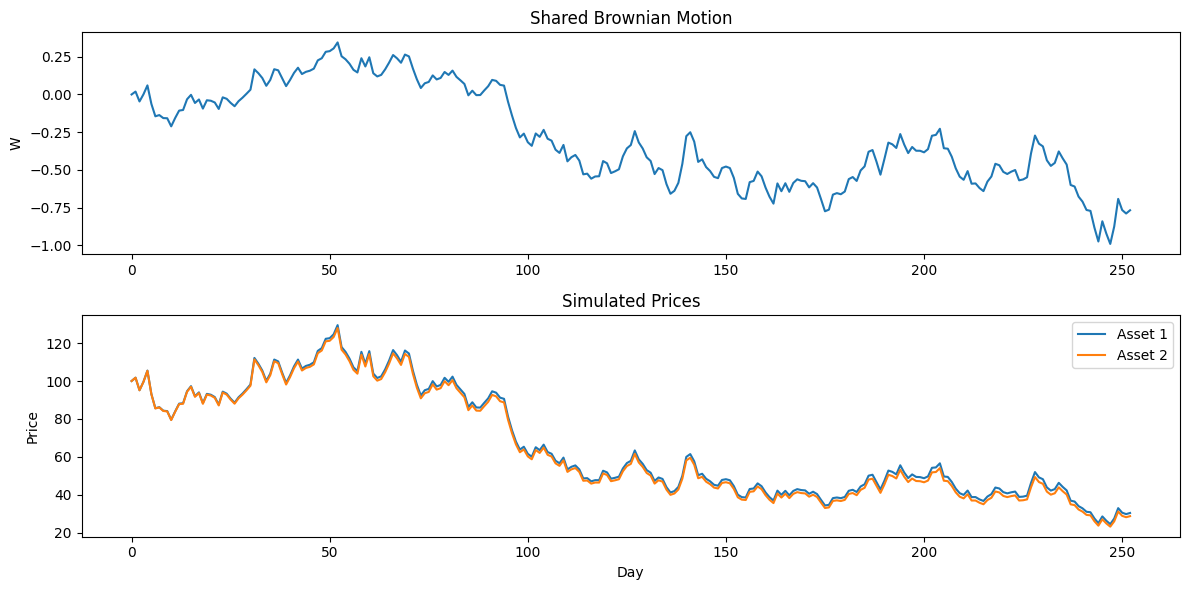

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(np.arange(n_steps + 1), W[:, 0])
axes[0].set_title("Shared Brownian Motion")
axes[0].set_ylabel("W")

axes[1].plot(prices.index, prices["Asset 1"], label="Asset 1")
axes[1].plot(prices.index, prices["Asset 2"], label="Asset 2")
axes[1].set_title("Simulated Prices")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Price")
axes[1].legend()

plt.tight_layout()
plt.show()

In [12]:
log_returns, simple_returns = calculate_returns(prices)
Omega_hat = estimate_covariance(log_returns.iloc[:L])
J_hat, selected_eigenvalues = estimate_directions(Omega_hat, k)
J_hat = align_directions(J_hat, J[:, None])[:, 0]

print(pd.DataFrame({"Known J": J, "Estimated J": J_hat}, index=assets).round(6))
print(f"\nSum of positions: {J_hat.sum():.6f}")
print(f"Length: {np.linalg.norm(J_hat):.6f}")
print(f"Shared-shock exposure: {(J_hat @ sigma).item():.6f}")
print(f"Selected eigenvalue (per step): {selected_eigenvalues[0]:.3e}")

          Known J  Estimated J
Cash     0.000000     0.000000
Asset 1  0.707107     0.707107
Asset 2 -0.707107    -0.707107

Sum of positions: 0.000000
Length: 1.000000
Shared-shock exposure: 0.000000
Selected eigenvalue (per step): 1.196e-19


In [13]:
detection = run_detector(prices, L, dt, k)
results = detection["results"]
estimated_drift = detection["drifts"]["Direction 1"]
true_signal = added_drift**2
mean_drift = estimated_drift.mean()
mean_detector = results["Detector"].mean()

print(pd.concat([estimated_drift.rename("Estimated drift"), results], axis=1).head(6).round(6))
print(f"\nKnown drift: {added_drift:.6f}")
print(f"Mean estimated drift: {mean_drift:.6f}")
print(f"Known squared drift: {true_signal:.6f}")
print(f"Mean detector: {mean_detector:.6f}")

      Estimated drift  Detector  Running mean
Step                                         
61           0.035912       NaN           NaN
62           0.039095  0.001404      0.001404
63           0.040340  0.001577      0.001491
64           0.041431  0.001671      0.001551
65           0.041758  0.001730      0.001596
66           0.041975  0.001753      0.001627

Known drift: 0.040000
Mean estimated drift: 0.039794
Known squared drift: 0.001600
Mean detector: 0.001585


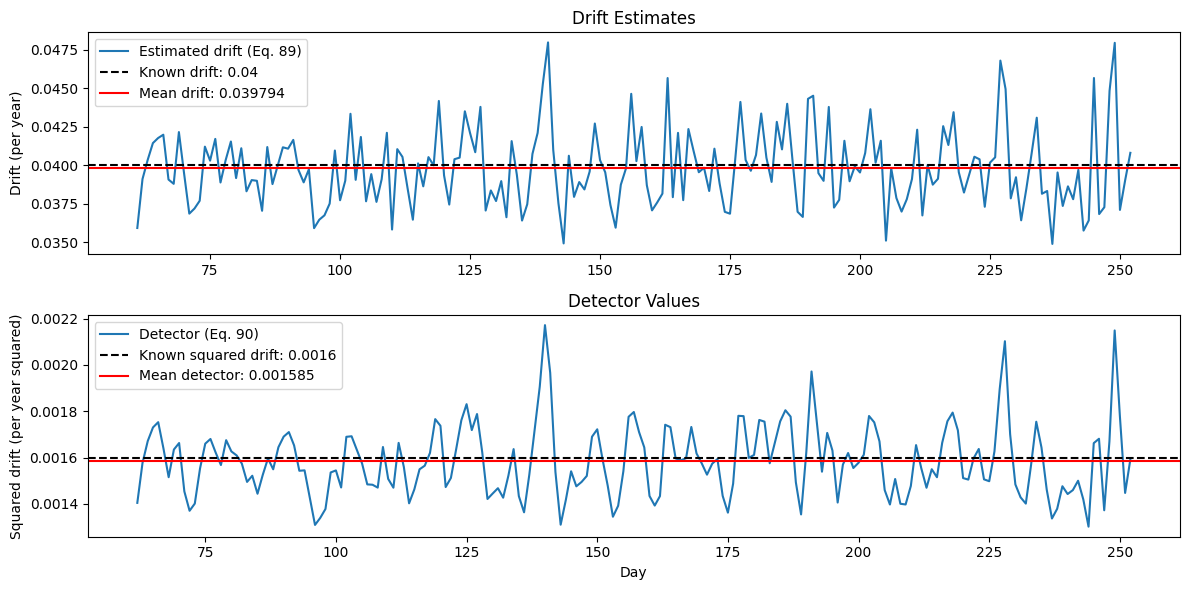

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(estimated_drift.index, estimated_drift, label="Estimated drift (Eq. 89)")
axes[0].axhline(added_drift, c="k", linestyle="--", label="Known drift: 0.04")
axes[0].axhline(mean_drift, c="r", label=f"Mean drift: {mean_drift:.6f}")
axes[0].set_title("Drift Estimates")
axes[0].set_ylabel("Drift (per year)")
axes[0].legend()

axes[1].plot(results.index, results["Detector"], label="Detector (Eq. 90)")
axes[1].axhline(true_signal, c="k", linestyle="--", label="Known squared drift: 0.0016")
axes[1].axhline(mean_detector, c="r", label=f"Mean detector: {mean_detector:.6f}")
axes[1].set_title("Detector Values")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Squared drift (per year squared)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
numeraire_check = check_numeraires(prices, L, dt, k)
mean_signals = numeraire_check["signals"].mean().to_frame("Mean detector")
mean_signals.index.name = "Pricing unit"
mean_signals["Known squared drift"] = true_signal
print(mean_signals.round(6))
print(f"\nLargest cross-unit range: {numeraire_check['summary']['Range'].max():.3e}")

fixed_detection = run_detector(prices, L, dt, k, rolling=False)
comparison = pd.DataFrame({
    "Mean detector": [mean_detector, fixed_detection["results"]["Detector"].mean()],
    "Known squared drift": [true_signal, true_signal],
}, index=["Rolling window", "Fixed window"])
print("\nEstimation choices:")
print(comparison.round(6))

              Mean detector  Known squared drift
Pricing unit                                    
Cash               0.001585               0.0016
Asset 1            0.001600               0.0016
Asset 2            0.001600               0.0016

Largest cross-unit range: 5.726e-04

Estimation choices:
                Mean detector  Known squared drift
Rolling window       0.001585               0.0016
Fixed window         0.001585               0.0016
